# Bring your own code, noise, and decoder

Install `pip install '.[notebooks]'`. This core-only example defines three small components in place; it does not import any script from `examples/`. Replace the marked matrices, noise law, and decoder with yours after checking the contracts. The associated paper is in preparation.

In [1]:
import os
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import Image, display
from mcmc4qec import spawn_seeds
QUICK = os.environ.get("MCMC4QEC_QUICK") == "1"
SEED = 2026
print(f"quick={QUICK}; root seed={SEED}")

quick=False; root seed=2026


`CSSCode` validates commuting stabilizers and logical pairing. In a bit-flip model, `hz` measures the X-error syndrome and `lz` maps a physical error to logical observables. A decoder must return a deterministic **logical prediction**, rather than an unlabelled physical correction.

In [2]:
import math
from itertools import product
from mcmc4qec import CSSCode, CallableDecoder, Problem, exact, direct_mc
# Replace these matrices with your binary CSS code.
code = CSSCode(hx=np.zeros((0, 3), dtype=int), hz=[[1, 1, 0], [0, 1, 1]],
               lx=[[1, 1, 1]], lz=[[1, 0, 0]])
# This example predicts the logical observable of a minimum-weight correction.
decoder = CallableDecoder(lambda syndrome: [int(tuple(syndrome) == (1, 0))],
                          identifier="three-bit-reference-logical-decoder-v1")
print(f"n={code.n}; k={code.lz.shape[0]}; decoder prediction={decoder.predict(np.array([1, 0], dtype=np.uint8))}")

n=3; k=1; decoder prediction=[1]


A custom noise's `sample` and normalized `log_prob` must describe the **same full state distribution**. We use unequal per-qubit rates and enumerate all eight states to check normalization. For correlated noise, calculate the joint probability; independent marginals would change both sampling and BAR ratios.

In [3]:
class UnequalBitFlip:
    n = 3
    alphabets = (2, 2, 2)
    scales = np.array([0.5, 1.0, 1.5])

    def sample(self, p, rng):
        rates = p * self.scales
        if np.any((rates < 0) | (rates > 1)):
            raise ValueError("rates must be in [0, 1]")
        return (rng.random(self.n) < rates).astype(np.uint8)

    def log_prob(self, state, p):
        rates = p * self.scales
        state = np.asarray(state)
        if np.any((rates < 0) | (rates > 1)) or state.shape != (self.n,) or np.any((state != 0) & (state != 1)):
            raise ValueError("invalid rate or state")
        values = np.where(state, rates, 1 - rates)
        return float(np.log(values).sum()) if np.all(values > 0) else -math.inf

    def metadata(self):
        return {"identifier": "unequal-bit-flip-v1", "scales": self.scales.tolist()}

noise = UnequalBitFlip()
p = .25
normalization = sum(math.exp(noise.log_prob(bits, p)) for bits in product((0, 1), repeat=3))
assert np.isclose(normalization, 1.0)
problem = Problem(code.bit_flip_model(), noise, decoder)
reference = exact(problem, p)
mc_seed = spawn_seeds(SEED, 1)[0]
mc = direct_mc(problem, p, trials=180 if QUICK else 2000, seed=mc_seed)
print(f"Normalization={normalization:.6f}; exact P_L={reference.estimate:.6f}; direct MC P_L={mc.estimate:.6f}")

Normalization=1.000000; exact P_L=0.148438; direct MC P_L=0.153000


Absolute `P_L` above comes from exact enumeration or direct MC. A failure-conditioned chain can only estimate observables **given failure**; its state frequency cannot yield absolute `P_L`. If you add a BAR ladder, keep one decoder and failure predicate fixed across rungs, or explicitly use `p_dependent_decoder_approx` and state that its interval omits decoder-dependent bias. An MC anchor must observe failures; an exact anchor avoids that issue here. A coarse ladder may raise `OverlapError` if adjacent observed support does not overlap. Custom failure predicates are not automatically stabilizer invariant; verify that property before enabling stabilizer flips.

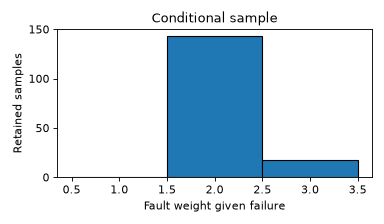

Chain E[w|faulty]=2.106; exact E[w|faulty]=2.079
Diagnostics are not proof of convergence, ergodicity, or correctness.


In [4]:
from mcmc4qec import KernelConfig, SamplingConfig, sample_faulty
chain_seed = spawn_seeds(SEED, 2)[1]
chain = sample_faulty(problem, p,
    config=SamplingConfig(samples=40 if QUICK else 160, burn_in=15 if QUICK else 50,
                          kernels=KernelConfig(cluster_k=1)), seed=chain_seed)
weights = np.count_nonzero(chain.states, axis=-1).ravel()
fig, ax = plt.subplots(figsize=(4.8, 2.8))
ax.hist(weights, bins=np.arange(.5, 4.5, 1), edgecolor="black")
ax.set(xlabel="Fault weight given failure", ylabel="Retained samples", title="Conditional sample")
fig.tight_layout()
buffer = BytesIO()
fig.savefig(buffer, format="png", dpi=80)
display(Image(data=buffer.getvalue()))
plt.close(fig)
print(f"Chain E[w|faulty]={weights.mean():.3f}; exact E[w|faulty]={reference.conditional_weight:.3f}")
print("Diagnostics are not proof of convergence, ergodicity, or correctness.")

This notebook uses a static bit-flip state space. A physical circuit fault model instead requires `KernelConfig(circuit_single=1, single=0, zanella=0, cluster=0, stabilizer=0)`; its Z, H, and stabilizer moves are unsupported.